# Denis' assignment with my mask midline, 4-fish Kaden recordings: summary per video

Output of `denis_mask_midline_kaden_4fish.py`: Denis' pipeline (his 1/r field with mirror images, no refractory step, highest
cosine similarity wins) with my mask midline (fish_midline_with_head on Kaden's visible masks) on the 14 recordings of
20 Feb 2024 tracked by Kaden, electrodes `electrodes_signed_px_coord_4-fish.csv`. Masks taken at video frame `Frame + offset`,
offset 0 and −5 (−5 fitted best on the 2-fish control). Identity = Kaden's letters A–D.

Per video and offset:
- **mean best similarity**: mean over assigned EODs of the highest cosine similarity (the assigned fish's);
- **median L2 per fish**: over the EODs assigned to that fish, L2 between the recorded and its predicted 10-pair pattern, each max-normalized (max |v| = 1);
- **% refractory violations**: among consecutive assigned EODs (in time, `RelativeTime` = EOD time), the % of pairs less than
  6 ms apart that went to the same fish. Also given: the % of consecutive pairs that are under 6 ms apart at all, and the
  % expected by chance if each EOD were given to a fish at random with the observed fish proportions (Σ p²).

EODs where a fish had no mask midline are not assigned and are left out (1.7%).

In [1]:
import glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DIR = 'results/eod_assign_4fish/denis_mask_midline_kaden'
FISH, OFFSETS, REFRACTORY_MS = 'ABCD', ['+0', '-5'], 6.0
COLORS = {'A': 'C0', 'B': 'C1', 'C': 'C2', 'D': 'C3'}
OFFSET_STYLE = {'+0': dict(color='0.55', marker='o'), '-5': dict(color='k', marker='s')}

def load(path):
    '''Assigned EODs of one output CSV (no midline columns), in time order.'''
    cols = ['RelativeTime', 'discharging_fish'] + [f'similarity_{f}' for f in FISH] + [f'recorded_PTP_pair{p}' for p in range(1, 11)] \
           + [f'predicted_PTP_{f}_pair{p}' for f in FISH for p in range(1, 11)]
    d = pd.read_csv(path, usecols=cols).dropna(subset=['discharging_fish']).sort_values('RelativeTime', kind='stable')
    return d.reset_index(drop=True)

def summary(d):
    '''Mean best similarity, median L2 per fish, refractory violations of one video.'''
    n = len(d)
    R = d[[f'recorded_PTP_pair{p}' for p in range(1, 11)]].to_numpy(); R = R / np.abs(R).max(1, keepdims=True)
    U = np.stack([d[[f'predicted_PTP_{f}_pair{p}' for p in range(1, 11)]].to_numpy() for f in FISH], axis=1)
    U = U / np.abs(U).max(2, keepdims=True)
    k = d.discharging_fish.map(FISH.index).to_numpy()
    l2 = np.linalg.norm(R - U[np.arange(n), k], axis=1)
    out = dict(EODs=n, mean_best_similarity=d[[f'similarity_{f}' for f in FISH]].max(axis=1).mean())
    for i, f in enumerate(FISH):
        out[f'% EODs {f}'] = 100 * np.mean(k == i)
        out[f'median L2 {f}'] = np.median(l2[k == i])
    dt = np.diff(d.RelativeTime.to_numpy()) * 1000
    close, same = dt < REFRACTORY_MS, k[1:] == k[:-1]
    p = np.bincount(k, minlength=4) / n
    out['% consecutive pairs < 6 ms'] = 100 * close.mean()
    out['% refractory violations'] = 100 * np.mean(close & same)                      # of all consecutive pairs
    out['% of pairs < 6 ms on the same fish'] = 100 * same[close].mean()
    out['% same fish by chance'] = 100 * np.sum(p ** 2)
    return out

rows = []
for off in OFFSETS:
    for path in sorted(glob.glob(f'{DIR}/denis_mask_midline_*_offset{off}.csv')):
        video = path.split('/')[-1].removeprefix('denis_mask_midline_').split('_offset')[0]
        rows.append(dict(video=video, offset=int(off), **summary(load(path))))
S = pd.DataFrame(rows)
S.to_csv(f'{DIR}/summary_per_video.csv', index=False)
print(f"{S.EODs.sum() // 2:,} assigned EODs per offset over {S.video.nunique()} videos")

802,330 assigned EODs per offset over 14 videos


## 1. Mean best similarity

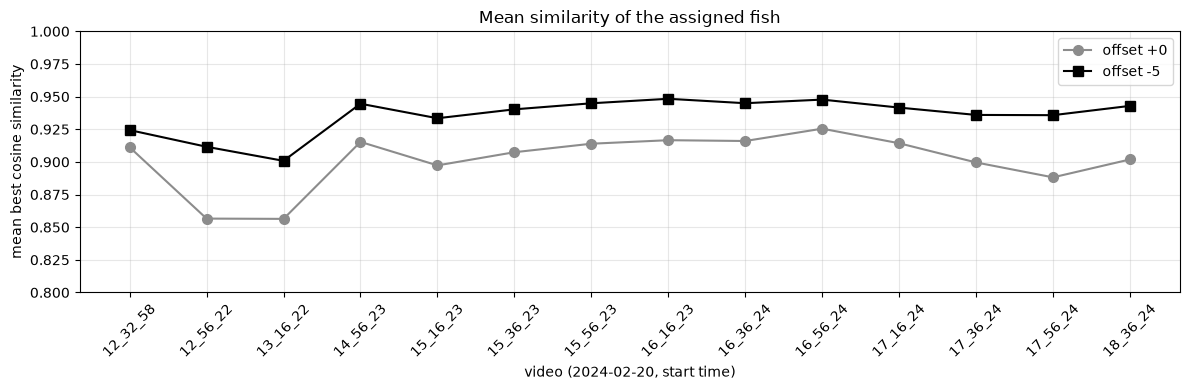

In [2]:
videos = sorted(S.video.unique()); x = np.arange(len(videos))
fig, ax = plt.subplots(figsize=(12, 4))
for off in OFFSETS:
    s = S[S.offset == int(off)].set_index('video').loc[videos]
    ax.plot(x, s.mean_best_similarity, lw=1.5, ms=7, label=f'offset {off}', **OFFSET_STYLE[off])
ax.set(xticks=x, xticklabels=videos, xlabel='video (2024-02-20, start time)', ylabel='mean best cosine similarity', ylim=(0.8, 1),
       title='Mean similarity of the assigned fish')
ax.tick_params(axis='x', rotation=45); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(f'{DIR}/mean_best_similarity_per_video.png', dpi=130); plt.show()

## 2. Median L2 per fish

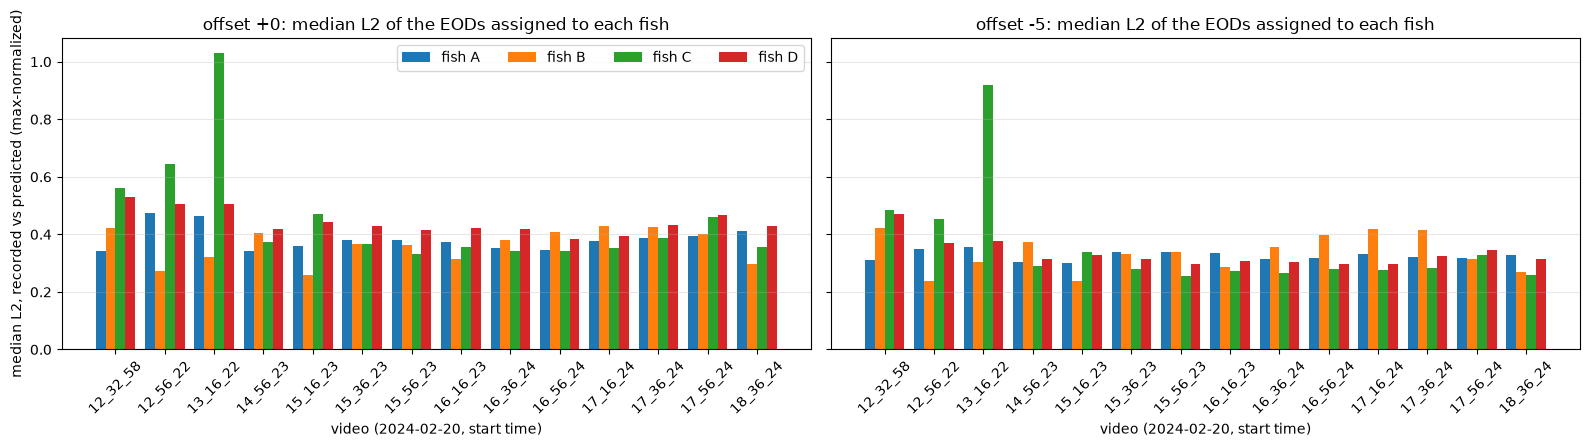

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for a, off in zip(axs, OFFSETS):
    s = S[S.offset == int(off)].set_index('video').loc[videos]
    for j, f in enumerate(FISH):
        a.bar(x + (j - 1.5) * 0.2, s[f'median L2 {f}'], 0.2, color=COLORS[f], label=f'fish {f}')
    a.set(xticks=x, xticklabels=videos, title=f'offset {off}: median L2 of the EODs assigned to each fish',
          xlabel='video (2024-02-20, start time)')
    a.tick_params(axis='x', rotation=45); a.grid(axis='y', alpha=0.3)
axs[0].set_ylabel('median L2, recorded vs predicted (max-normalized)'); axs[0].legend(ncol=4)
plt.tight_layout(); fig.savefig(f'{DIR}/median_l2_per_fish_per_video.png', dpi=130); plt.show()

## 3. Refractory violations (two consecutive EODs on the same fish, < 6 ms apart)

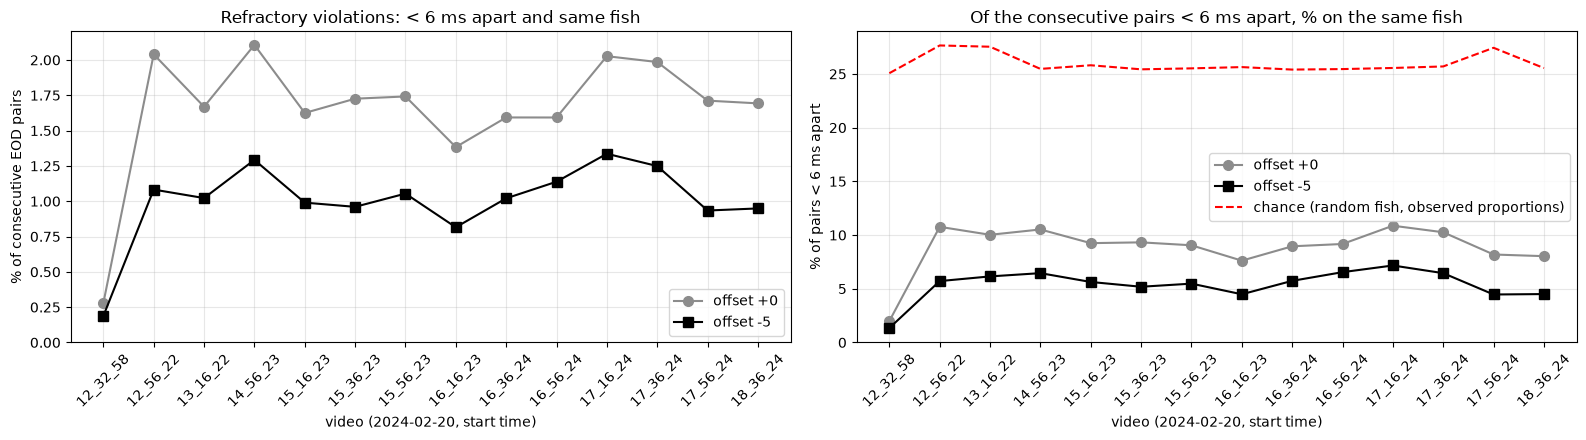

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
for off in OFFSETS:
    s = S[S.offset == int(off)].set_index('video').loc[videos]
    axs[0].plot(x, s['% refractory violations'], lw=1.5, ms=7, label=f'offset {off}', **OFFSET_STYLE[off])
    axs[1].plot(x, s['% of pairs < 6 ms on the same fish'], lw=1.5, ms=7, label=f'offset {off}', **OFFSET_STYLE[off])
s0 = S[S.offset == 0].set_index('video').loc[videos]
axs[1].plot(x, s0['% same fish by chance'], 'r--', lw=1.5, label='chance (random fish, observed proportions)')
axs[0].set(ylabel='% of consecutive EOD pairs', title='Refractory violations: < 6 ms apart and same fish')
axs[1].set(ylabel='% of pairs < 6 ms apart', title='Of the consecutive pairs < 6 ms apart, % on the same fish', ylim=(0, None))
for a in axs:
    a.set(xticks=x, xticklabels=videos, xlabel='video (2024-02-20, start time)'); a.tick_params(axis='x', rotation=45)
    a.legend(); a.grid(alpha=0.3); a.set_ylim(bottom=0)
plt.tight_layout(); fig.savefig(f'{DIR}/refractory_violations_per_video.png', dpi=130); plt.show()

## 4. Table

In [5]:
cols = ['EODs', 'mean_best_similarity'] + [f'median L2 {f}' for f in FISH] + [f'% EODs {f}' for f in FISH] + \
       ['% consecutive pairs < 6 ms', '% refractory violations', '% of pairs < 6 ms on the same fish', '% same fish by chance']
T = S.set_index(['video', 'offset'])[cols].sort_index()
display(T.round(3))
print('over all videos (EOD-weighted means):')
w = S.groupby('offset').apply(lambda g: pd.Series({c: np.average(g[c], weights=g.EODs) for c in cols[1:]}), include_groups=False)
display(w.round(3))

EODs  mean_best_similarity  median L2 A  median L2 B  \
video    offset                                                          
12_32_58 -5      20802                 0.924        0.313        0.421   
          0      20815                 0.911        0.342        0.422   
12_56_22 -5      66606                 0.912        0.351        0.240   
          0      66612                 0.857        0.476        0.272   
13_16_22 -5      60939                 0.901        0.357        0.302   
          0      60999                 0.856        0.463        0.323   
14_56_23 -5      57877                 0.945        0.305        0.374   
          0      57911                 0.915        0.342        0.404   
15_16_23 -5      59290                 0.933        0.300        0.239   
          0      59333                 0.897        0.360        0.258   
15_36_23 -5      59572                 0.940        0.337        0.331   
          0      59624                 0.907        0.381        0.367   
15_56_23 -5      58449                 0.945        0.339        0.340   
          0      58508                 0.914        0.380        0.364   
16_16_23 -5      59832                 0.948        0.336        0.288   
          0      59856                 0.917        0.374        0.315   
16_36_24 -5      55958                 0.945        0.316        0.357   
          0      55994                 0.916        0.351        0.380   
16_56_24 -5      51230                 0.948        0.316        0.399   
          0      51235                 0.925        0.346        0.408   
17_16_24 -5      54714                 0.942        0.330        0.418   
          0      54720                 0.914        0.378        0.430   
17_36_24 -5      62774                 0.936        0.320        0.415   
          0      62809                 0.900        0.387        0.427   
17_56_24 -5      67973                 0.936        0.319        0.316   
          0      68047                 0.888        0.395        0.401   
18_36_24 -5      66074                 0.943        0.328        0.269   
          0      66108                 0.902        0.410        0.296   

                 median L2 C  median L2 D  % EODs A  % EODs B  % EODs C  \
video    offset                                                           
12_32_58 -5            0.485        0.472    26.896    24.488    25.195   
          0            0.562        0.532    26.976    24.737    25.001   
12_56_22 -5            0.453        0.369    33.908    15.347    17.890   
          0            0.645        0.505    34.530    16.252    17.630   
13_16_22 -5            0.918        0.376    31.768    15.944    17.278   
          0            1.030        0.505    32.068    16.843    17.290   
14_56_23 -5            0.291        0.316    21.869    21.347    31.598   
          0            0.373        0.419    22.032    22.481    30.631   
15_16_23 -5            0.340        0.329    27.843    17.274    24.491   
          0            0.471        0.444    27.934    18.071    24.160   
15_36_23 -5            0.281        0.315    26.234    18.606    28.688   
          0            0.368        0.430    26.340    19.459    27.984   
15_56_23 -5            0.255        0.299    25.621    18.638    30.565   
          0            0.330        0.416    25.949    19.621    29.688   
16_16_23 -5            0.273        0.308    26.842    17.489    28.271   
          0            0.356        0.422    26.978    18.113    27.835   
16_36_24 -5            0.265        0.303    25.385    19.756    30.142   
          0            0.344        0.420    25.531    20.354    29.316   
16_56_24 -5            0.281        0.297    22.485    22.877    31.856   
          0            0.341        0.384    22.625    23.589    30.793   
17_16_24 -5            0.276        0.296    24.895    19.743    31.802   
          0            0.352        0.395    25.174    20.577    30.788 

over all videos (EOD-weighted means):


,mean_best_similarity,median L2 A,median L2 B,median L2 C,median L2 D,% EODs A,% EODs B,% EODs C,% EODs D,% consecutive pairs < 6 ms,% refractory violations,% of pairs < 6 ms on the same fish,% same fish by chance
offset,,,,,,,,,,,,,
-5,0.936,0.327,0.330,0.352,0.328,27.503,17.897,27.024,27.576,18.718,1.038,5.540,26.217
0,0.900,0.389,0.357,0.455,0.440,27.695,18.728,26.461,27.115,18.720,1.725,9.181,26.026
